In [17]:
import os

In [18]:
import pandas as pd
import numpy as np
import torch
import torchvision
from torchvision.transforms import v2 as T
from pathlib import Path
import matplotlib.pyplot as plt

In [19]:
from torch.utils.data import DataLoader, Subset, Dataset

In [20]:
from PIL import Image

In [21]:
attributes=pd.read_csv("/kaggle/input/datasets/adityajigyasu/celebrity-dataset/celeba/list_attr_celeba.txt")

In [22]:
attributes.to_csv('attributes.csv',index=None)

In [23]:
count=0
for r in attributes.iloc[0].to_string().split():
    print(r)
    print()

202599

5_o_Clock_Shadow

Arched_Eyebrows

Attractive

Ba...



In [24]:
count=0
for i in attributes.iloc[0].to_list()[0].split():
    print(i)
    count=count+1
print(count)

5_o_Clock_Shadow
Arched_Eyebrows
Attractive
Bags_Under_Eyes
Bald
Bangs
Big_Lips
Big_Nose
Black_Hair
Blond_Hair
Blurry
Brown_Hair
Bushy_Eyebrows
Chubby
Double_Chin
Eyeglasses
Goatee
Gray_Hair
Heavy_Makeup
High_Cheekbones
Male
Mouth_Slightly_Open
Mustache
Narrow_Eyes
No_Beard
Oval_Face
Pale_Skin
Pointy_Nose
Receding_Hairline
Rosy_Cheeks
Sideburns
Smiling
Straight_Hair
Wavy_Hair
Wearing_Earrings
Wearing_Hat
Wearing_Lipstick
Wearing_Necklace
Wearing_Necktie
Young
40


In [25]:
print(attributes.iloc[0].to_string())

202599    5_o_Clock_Shadow Arched_Eyebrows Attractive Ba...


In [26]:
features=attributes.iloc[0].to_list()[0].split()


In [27]:
column_name=[]
for i,_ in enumerate(features):
    column_name.append(i)

In [28]:
attributes=attributes.iloc[1:,0].str.split(expand=True)
attributes.columns=['image_file']+column_name


In [29]:
attributes

,image_file,0,1,2,3,4,5,6,7,8,...,30,31,32,33,34,35,36,37,38,39
1,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
2,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
3,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
4,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
5,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202595,202595.jpg,-1,-1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
202596,202596.jpg,-1,-1,-1,-1,-1,1,1,-1,-1,...,-1,1,1,-1,-1,-1,-1,-1,-1,1
202597,202597.jpg,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
202598,202598.jpg,-1,1,1,-1,-1,-1,1,-1,1,...,-1,1,-1,1,1,-1,1,-1,-1,1


In [30]:
attributes[column_name]=attributes[column_name].astype(int)

In [31]:
attributes

,image_file,0,1,2,3,4,5,6,7,8,...,30,31,32,33,34,35,36,37,38,39
1,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
2,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
3,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
4,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
5,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202595,202595.jpg,-1,-1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1
202596,202596.jpg,-1,-1,-1,-1,-1,1,1,-1,-1,...,-1,1,1,-1,-1,-1,-1,-1,-1,1
202597,202597.jpg,-1,-1,-1,-1,-1,-1,-1,-1,1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
202598,202598.jpg,-1,1,1,-1,-1,-1,1,-1,1,...,-1,1,-1,1,1,-1,1,-1,-1,1


In [32]:
features[31]

'Smiling'

In [33]:
smiling_attr=attributes[31].to_list()

In [34]:
image_repo=Path('/kaggle/input/datasets/adityajigyasu/celebrity-dataset/celeba/img_align_celeba/img_align_celeba')

In [35]:
image_repo=[image for image in image_repo.iterdir()]

In [36]:
len(image_repo)

202599

In [37]:
class CelebDataset(Dataset):
    
    def __init__(self,image,labels,transforms=None):
        super().__init__()
        self.image=image
        self.labels=labels
        self.transforms=transforms
    def __len__(self):
        return len(self.image)
    def __getitem__(self,idx):
        img=self.image[idx]
        img=Image.open(img).convert('RGB')
        if self.transforms:
            img=self.transforms(img)
        label=self.labels[idx]
        return img,label

In [38]:
import pandas as pd

data={0:[1,2,3],1:[2,3,4]}
df=pd.DataFrame(data,index=['A','B','C'])

In [39]:
df

,0,1
A,1,2
B,2,3
C,3,4


In [40]:
dataset=CelebDataset(image_repo,smiling_attr)

In [41]:
import random

In [42]:
smile=[]
non_smile=[]
for i,label in enumerate(smiling_attr):
    if label==1:
      smile.append(i)
    else:
      non_smile.append(i)

In [43]:
smile_sample=random.sample(smile,len(smile))
non_smile_sample=random.sample(non_smile,len(non_smile))

In [44]:
print("Same size divide:",len(smile)+len(non_smile)==len(smiling_attr))

Same size divide: True


In [45]:
len_train_smile=int(0.7*len(smile_sample))
len_val_smile=len_train_smile+int(0.15*len(smile_sample))

train_smile_idx=smile_sample[:len_train_smile]
val_smile_idx=smile_sample[len_train_smile:len_val_smile]
test_smile_idx=smile_sample[len_val_smile:]

In [46]:
len_train_non_smile=int(0.7*len(non_smile_sample))
len_val_non_smile=len_train_non_smile+int(0.15*len(non_smile_sample))

train_non_smile_idx=non_smile_sample[:len_train_non_smile]
val_non_smile_idx=non_smile_sample[len_train_non_smile:len_val_non_smile]
test_non_smile_idx=non_smile_sample[len_val_non_smile:]

In [47]:
train_idx=train_smile_idx+train_non_smile_idx
test_idx=test_smile_idx+test_non_smile_idx
val_idx=val_smile_idx+val_non_smile_idx

train_idx=random.sample(train_idx,len(train_idx))
test_idx=random.sample(test_idx,len(test_idx))
val_idx=random.sample(val_idx,len(val_idx))

In [48]:
train_dataset=Subset(dataset,train_idx)
val_dataset=Subset(dataset,val_idx)
test_dataset=Subset(dataset,test_idx)

In [49]:
from torchvision import transforms

In [50]:
img,attr=train_dataset[0]

In [51]:
print(img.dtype if hasattr(img, 'dtype') else "No dtype")

No dtype


In [52]:
from collections import Counter
image_label_count=Counter()
for i,(_,label) in enumerate(train_dataset):
    if i==100:
        break
    image_label_count[label]+=1

In [53]:
image_label_count

Counter({1: 40, -1: 60})

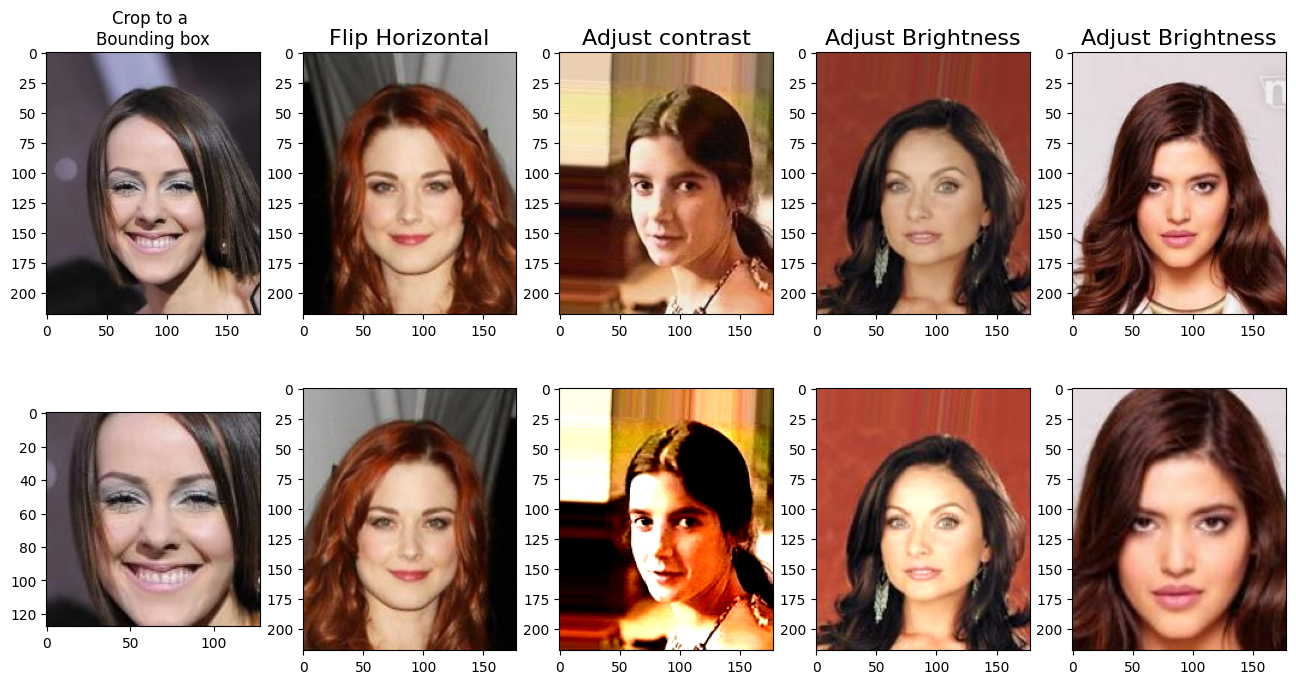

In [54]:
fig=plt.figure(figsize=(16,8))
ax=fig.add_subplot(2,5,1)
img,attr=train_dataset[0]
ax.set_title('Crop to a \nBounding box')
ax.imshow(img)
ax=fig.add_subplot(2,5,6)
img_transformed=transforms.functional.crop(img,60,20,128,128)
ax.imshow(img_transformed)

ax=fig.add_subplot(2,5,2)
img,attr=train_dataset[1]
ax.imshow(img)
ax.set_title('Flip Horizontal',size=16)
img_transformed=transforms.functional.hflip(img)
ax=fig.add_subplot(2,5,7)
ax.imshow(img_transformed)

ax=fig.add_subplot(2,5,3)
img,attr=train_dataset[2]
ax.imshow(img)
ax.set_title('Adjust contrast',size=16)
img_transformed=transforms.functional.adjust_contrast(img,contrast_factor=2)
ax=fig.add_subplot(2,5,8)
ax.imshow(img_transformed)

ax=fig.add_subplot(2,5,4)
img,attr=train_dataset[3]
ax.imshow(img)
ax.set_title('Adjust Brightness',size=16)
img_transformed=transforms.functional.adjust_brightness(img,brightness_factor=1.3)
ax=fig.add_subplot(2,5,9)
ax.imshow(img_transformed)

ax=fig.add_subplot(2,5,5)
img,attr=train_dataset[4]
ax.imshow(img)
ax.set_title('Adjust Brightness',size=16)
img_center_crop = transforms.functional.center_crop(img, [0.7*218, 0.7*178])
img_resized = transforms.functional.resize(img_center_crop, size=(218, 178))
ax=fig.add_subplot(2,5,10)
ax.imshow(img_resized)

plt.show()

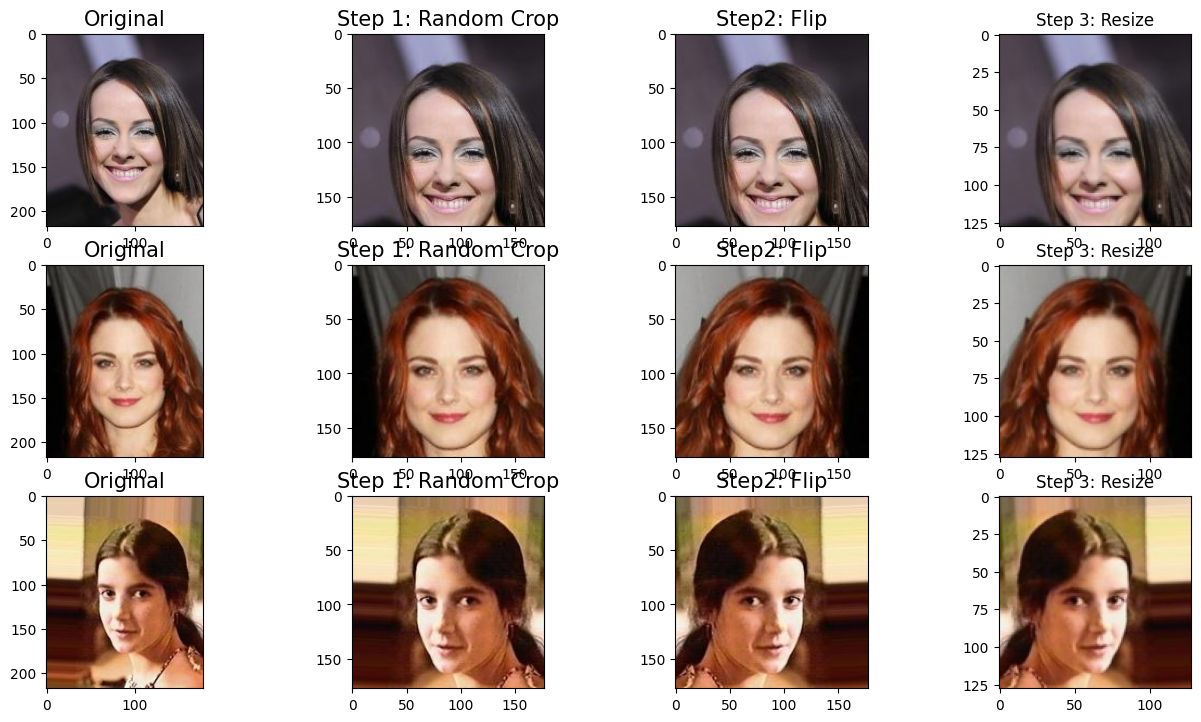

In [55]:
fig,ax=plt.subplots(3,4,figsize=(16,8.5))
ax=ax.ravel()

for i,(image,label) in enumerate(train_dataset):
    if i==3:
        break
    ax[4*i].imshow(image)
    ax[4*i].set_title("Original",size=15)
    image_transforms=transforms.Compose([transforms.RandomCrop([178,178])])
    img_cropped=image_transforms(image)
    ax[4*i+1].imshow(img_cropped)
    ax[4*i+1].set_title('Step 1: Random Crop',size=15)
    image_transform=transforms.Compose([transforms.RandomHorizontalFlip()])
    img_inverted=image_transform(img_cropped)
    ax[4*i+2].imshow(img_inverted)
    ax[4*i+2].set_title('Step2: Flip',size=15)
    img_resized=transforms.functional.resize(img_inverted,size=(128,128))
    ax[4*i+3].imshow(img_resized)
    ax[4*i+3].set_title('Step 3: Resize')
    

In [58]:
train_transforms=T.Compose([
    T.ToImage(),
    T.RandomCrop([178,178]),
    T.RandomHorizontalFlip(),
    T.Resize([64,64]),
    T.ToDtype(torch.float32,scale=True)
])

In [59]:
celeb_dataset=CelebDataset(image_repo,smiling_attr,transforms=train_transforms)
train_dataset=Subset(celeb_dataset,train_idx)
test_dataset=Subset(celeb_dataset,test_idx)
val_dataset=Subset(celeb_dataset,val_idx)


In [61]:
from torch.utils.data import DataLoader

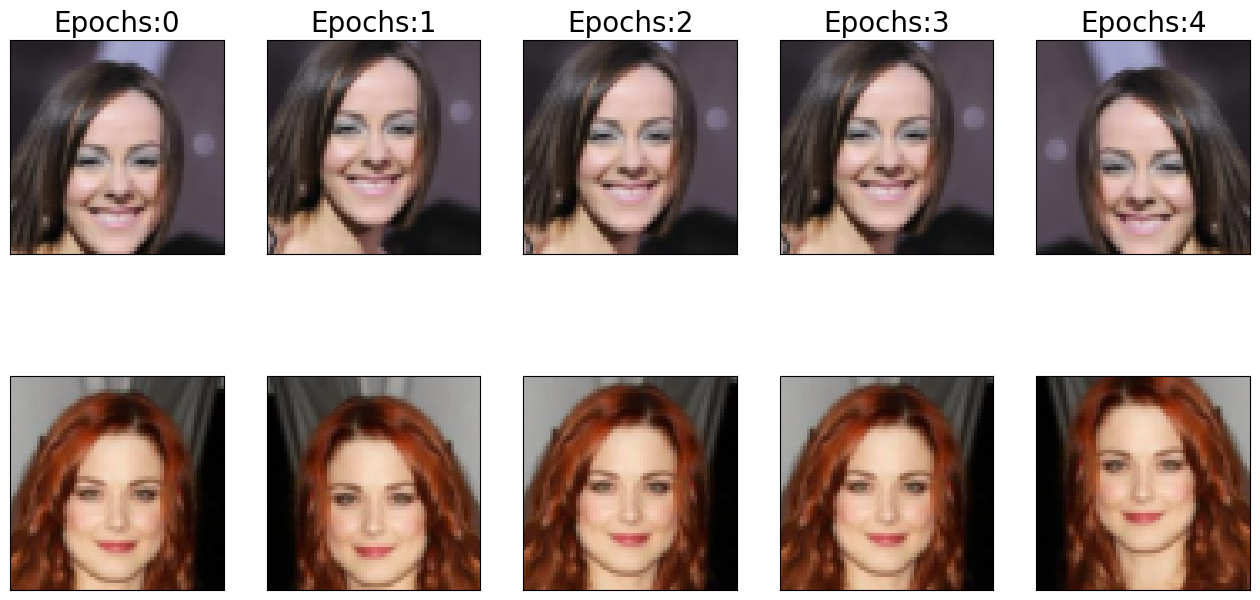

In [97]:
train_dataloader=DataLoader(train_dataset,batch_size=2);
fig,ax=plt.subplots(2,5,figsize=(16,8))

for epochs in range(5):
        image_batch,label_batch=next(iter(train_dataloader))
        image_batch=image_batch.permute(0,2,3,1)
        image1=image_batch[0]
        image2=image_batch[1]
        
        ax[0][epochs].imshow(image1)
        ax[0][epochs].set_title(f"Epochs:{epochs}",size=20)
        ax[0][epochs].set_xticks([])
        ax[0][epochs].set_yticks([])
        ax[1][epochs].imshow(image2)
   
        ax[1][epochs].set_xticks([])
        ax[1][epochs].set_yticks([])